In [ ]:
import os

if os.getenv("COLAB_RELEASE_TAG"):
  print("Ejecutando en Colab")

  print("Instalando SUMO y dependencias...")
  !add-apt-repository ppa:sumo/stable -y > /dev/null 2>&1
  !apt-get update -q > /dev/null 2>&1
  !apt-get install sumo sumo-tools -y > /dev/null 2>&1
  os.environ['SUMO_HOME'] = "/usr/share/sumo"

  !pip install sumo-rl gymnasium torch matplotlib numpy snntorch -q
  print("¡Entorno configurado correctamente!")
else:
  print("No ejecutando en Colab")

  import sumo
  # Asegurar que SUMO_HOME apunte dinámicamente a la ruta de SUMO instalada por pip
  os.environ['SUMO_HOME'] = sumo.SUMO_HOME

No ejecutando en Colab


In [16]:
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

import sumo_rl
from sumo_rl import SumoEnvironment

# Fijar semillas para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo de cómputo: {device}")

# Hiperparámetros de RL
EPISODES = 30              # Episodios de entrenamiento
SIM_SECONDS = 3600         # Segundos de simulación por episodio (1 hora simulada)
DELTA_TIME = 5             # El agente toma decisiones cada 5 segundos de simulación
BATCH_SIZE = 64
GAMMA = 0.99               # Factor de descuento
LR = 1e-3                  # Tasa de aprendizaje
EPS_START = 1.0            # Exploración inicial
EPS_END = 0.05             # Exploración mínima
EPS_DECAY = 0.90          # Tasa de decaimiento de epsilon
TARGET_UPDATE = 5          # Frecuencia de actualización de Target Network (en episodios)

# Localizar los archivos de la intersección incluidos dentro de sumo-rl
NET_FILE = os.path.join(sumo_rl.__path__[0], 'nets', 'single-intersection', 'single-intersection.net.xml')
ROUTE_FILE = os.path.join(sumo_rl.__path__[0], 'nets', 'single-intersection', 'single-intersection.rou.xml')

# Función generadora del entorno
def make_env(use_gui=False):
    return SumoEnvironment(
        net_file=NET_FILE,
        route_file=ROUTE_FILE,
        out_csv_name=None,
        use_gui=use_gui,
        num_seconds=SIM_SECONDS,
        delta_time=DELTA_TIME,
        single_agent=True   # IMPORTANTE: Para que devuelva estados y acepte acciones estándar de Gymnasium
    )

Dispositivo de cómputo: cuda


In [17]:
# 1. Arquitectura de la Red Neuronal Clásica (Baseline ANN)
class DQN(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim) # Salida: Valores Q para cada fase del semáforo
        )

    def forward(self, x):
        return self.net(x)

# 2. Buffer de Experiencia (Replay Memory)
class ReplayBuffer:
    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        state, action, reward, next_state, done = zip(*random.sample(self.buffer, batch_size))
        return (torch.FloatTensor(np.array(state)).to(device),
                torch.LongTensor(action).to(device),
                torch.FloatTensor(reward).to(device),
                torch.FloatTensor(np.array(next_state)).to(device),
                torch.FloatTensor(done).to(device))

    def __len__(self):
        return len(self.buffer)

In [18]:
class DQNAgent:
    def __init__(self, state_dim, action_dim):
        self.action_dim = action_dim
        self.epsilon = EPS_START
        
        # Redes Q principal y Target
        self.policy_net = DQN(state_dim, action_dim).to(device)
        self.target_net = DQN(state_dim, action_dim).to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=LR)
        self.loss_fn = nn.SmoothL1Loss() # Huber Loss para estabilidad
        self.memory = ReplayBuffer()

    def select_action(self, state, evaluate=False):
        if not evaluate and random.random() < self.epsilon:
            return random.randrange(self.action_dim)
        
        with torch.no_grad():
            state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)
            q_values = self.policy_net(state_tensor)
            return q_values.argmax().item()

    def update(self):
        if len(self.memory) < BATCH_SIZE:
            return 0.0

        states, actions, rewards, next_states, dones = self.memory.sample(BATCH_SIZE)

        # Q(s, a)
        curr_q = self.policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        # Target Q = r + gamma * max_a Q_target(s', a)
        with torch.no_grad():
            max_next_q = self.target_net(next_states).max(1)[0]
            target_q = rewards + (1 - dones) * GAMMA * max_next_q

        loss = self.loss_fn(curr_q, target_q)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.item()

    def decay_epsilon(self):
        self.epsilon = max(EPS_END, self.epsilon * EPS_DECAY)

In [19]:
def evaluate_fixed_time(episodes=3):
    print("Iniciando evaluación de Línea Base 1 (Tiempo Fijo)...")
    env = make_env()

    total_waiting_times = []
    
    for ep in range(episodes):
        obs, info = env.reset()
        done = False
        step = 0
        phase = 0
        episode_waiting_time = 0

        while not done:
            # Cambia de fase cada 30 segundos (6 pasos x 5s delta_time)
            if step % 6 == 0:
                phase = (phase + 1) % env.action_space.n

            next_obs, reward, terminated, truncated, info = env.step(phase)
            done = terminated or truncated
            episode_waiting_time += info.get('system_total_waiting_time', 0)
            step += 1

        total_waiting_times.append(episode_waiting_time / step)
    
    env.close()
    avg_wt = np.mean(total_waiting_times)
    print(f"Tiempo Fijo - Espera media promedio: {avg_wt:.2f} s")
    return avg_wt

fixed_baseline_wt = evaluate_fixed_time(episodes=3)

Iniciando evaluación de Línea Base 1 (Tiempo Fijo)...
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 3ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 6ms, vehicles TOT 2396 ACT 42 BUF 103)              
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 6ms, vehicles TOT 2459 ACT 41 BUF 110)              
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 10ms, vehicles TOT 2423 ACT 42 BUF 93)              
Tiempo Fijo - Espera media promedio: 175.76 s


In [20]:
# Instanciar el entorno de SUMO
env = make_env()

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
agent = DQNAgent(state_dim, action_dim)

reward_history = []
waiting_time_history = []
loss_history = []

print("Iniciando entrenamiento del Agente ANN-DQN...")

for ep in range(1, EPISODES + 1):
    state, info = env.reset()
    done = False
    ep_reward = 0.0
    ep_waiting_time = 0.0
    ep_losses = []
    step_count = 0

    while not done:
        action = agent.select_action(state)
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        # Guardar en memoria y entrenar
        agent.memory.push(state, action, reward, next_state, done)
        loss = agent.update()
        if loss > 0:
            ep_losses.append(loss)

        state = next_state
        ep_reward += reward
        ep_waiting_time += info.get('system_total_waiting_time', 0)
        step_count += 1

    agent.decay_epsilon()
    
    # Actualizar la Target Network
    if ep % TARGET_UPDATE == 0:
        agent.target_net.load_state_dict(agent.policy_net.state_dict())

    avg_ep_loss = np.mean(ep_losses) if ep_losses else 0.0
    avg_ep_waiting_time = ep_waiting_time / step_count

    reward_history.append(ep_reward)
    waiting_time_history.append(avg_ep_waiting_time)
    loss_history.append(avg_ep_loss)

    print(f"Episodio {ep}/{EPISODES} | Recompensa: {ep_reward:.1f} | "
          f"Espera Media: {avg_ep_waiting_time:.2f}s | Epsilon: {agent.epsilon:.2f} | Loss: {avg_ep_loss:.4f}")

env.close()

# Guardar los pesos del modelo base para el Entregable 2
torch.save(agent.policy_net.state_dict(), "ann_dqn_baseline.pth")
print("Modelo guardado como 'ann_dqn_baseline.pth'")

 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 2ms, vehicles TOT 0 ACT 0 BUF 0)                      
Iniciando entrenamiento del Agente ANN-DQN...
 Retrying in 1 seconds
Episodio 1/30 | Recompensa: -3.9 | Espera Media: 97.07s | Epsilon: 0.90 | Loss: 0.0516
Step #3600.00 (1ms ~= 1000.00*RT, ~40000.00UPS, TraCI: 16ms, vehicles TOT 2237 ACT 40 BUF 
 Retrying in 1 seconds
Episodio 2/30 | Recompensa: -4.8 | Espera Media: 71.06s | Epsilon: 0.81 | Loss: 0.0524
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 21ms, vehicles TOT 2263 ACT 39 BUF 287)             
 Retrying in 1 seconds
Episodio 3/30 | Recompensa: -1.2 | Espera Media: 59.94s | Epsilon: 0.73 | Loss: 0.0502
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 12ms, vehicles TOT 2309 ACT 37 BUF 217)             
 Retrying in 1 seconds
Episodio 4/30 | Recompensa: -1.5 | Espera Media: 46.73s | Epsilon: 0.66 | Loss: 0.0469
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 15ms, vehicles TOT 2518 ACT 43 BUF 49)              
 Retrying in 1 seconds
Episodio 5/30 

In [21]:
# Evaluar el agente entrenado sin exploración (Epsilon = 0)
eval_env = make_env()
state, info = eval_env.reset()
done = False
total_wait = 0
steps = 0

while not done:
    # evaluate=True fuerza a tomar siempre argmax Q(s, a)
    action = agent.select_action(state, evaluate=True)
    next_state, reward, terminated, truncated, info = eval_env.step(action)
    done = terminated or truncated
    total_wait += info.get('system_total_waiting_time', 0)
    steps += 1
    state = next_state

eval_env.close()
final_wait_time = total_wait / steps

print(f"--- RESULTADOS FINALES ---")
print(f"Línea Base (Tiempo Fijo): {fixed_baseline_wt:.2f} s")
print(f"ANN-DQN (Agente Entrenado): {final_wait_time:.2f} s")
print(f"Mejora: {((fixed_baseline_wt - final_wait_time) / fixed_baseline_wt) * 100:.1f}%")

 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 2ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 7ms, vehicles TOT 2404 ACT 42 BUF 167)              
--- RESULTADOS FINALES ---
Línea Base (Tiempo Fijo): 175.76 s
ANN-DQN (Agente Entrenado): 18.15 s
Mejora: 89.7%


In [22]:
def test_generalization(agent, n_tests=5):
    print("--- INICIANDO TEST DE EVALUACIÓN (GENERALIZACIÓN) ---")
    
    waiting_times = []
    queues = []
    
    for test_idx in range(n_tests):
        # Usamos una semilla completamente nueva para cada test
        test_seed = 1000 + test_idx
        
        test_env = SumoEnvironment(
            net_file=NET_FILE,
            route_file=ROUTE_FILE,
            use_gui=False,
            num_seconds=SIM_SECONDS,
            delta_time=DELTA_TIME,
            single_agent=True
        )
        
        # Iniciar simulación con la nueva semilla
        state, info = test_env.reset(seed=test_seed)
        done = False
        ep_waiting_time = 0
        ep_queue = 0
        steps = 0
        
        while not done:
            # evaluate=True: La red toma el 100% del control (cero exploración)
            action = agent.select_action(state, evaluate=True)
            next_state, reward, terminated, truncated, info = test_env.step(action)
            done = terminated or truncated
            
            # Extraer métricas reales de SUMO
            ep_waiting_time += info.get('system_total_waiting_time', 0)
            ep_queue += info.get('system_total_stopped', 0) # Autos totalmente parados
            steps += 1
            state = next_state
            
        test_env.close()
        
        avg_wait = ep_waiting_time / steps
        avg_q = ep_queue / steps
        waiting_times.append(avg_wait)
        queues.append(avg_q)
        
        print(f"Test {test_idx + 1} (Semilla {test_seed}) -> Espera media: {avg_wait:.2f} s | Cola media: {avg_q:.2f} autos")
        
    print("\n--- RESULTADOS FINALES DE GENERALIZACIÓN ---")
    print(f"Tiempo de espera: {np.mean(waiting_times):.2f} ± {np.std(waiting_times):.2f} s")
    print(f"Longitud de cola: {np.mean(queues):.2f} ± {np.std(queues):.2f} autos")

# Ejecutar el test con el agente que ya entrenaste
test_generalization(agent, n_tests=5)

--- INICIANDO TEST DE EVALUACIÓN (GENERALIZACIÓN) ---
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 3ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (1ms ~= 1000.00*RT, ~39000.00UPS, TraCI: 7ms, vehicles TOT 2420 ACT 39 BUF 9
Test 1 (Semilla 1000) -> Espera media: 16.78 s | Cola media: 5.00 autos
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 3ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 7ms, vehicles TOT 2375 ACT 40 BUF 179)              
Test 2 (Semilla 1001) -> Espera media: 17.62 s | Cola media: 5.33 autos
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 4ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 17ms, vehicles TOT 2380 ACT 41 BUF 114)             
Test 3 (Semilla 1002) -> Espera media: 18.23 s | Cola media: 5.50 autos
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS

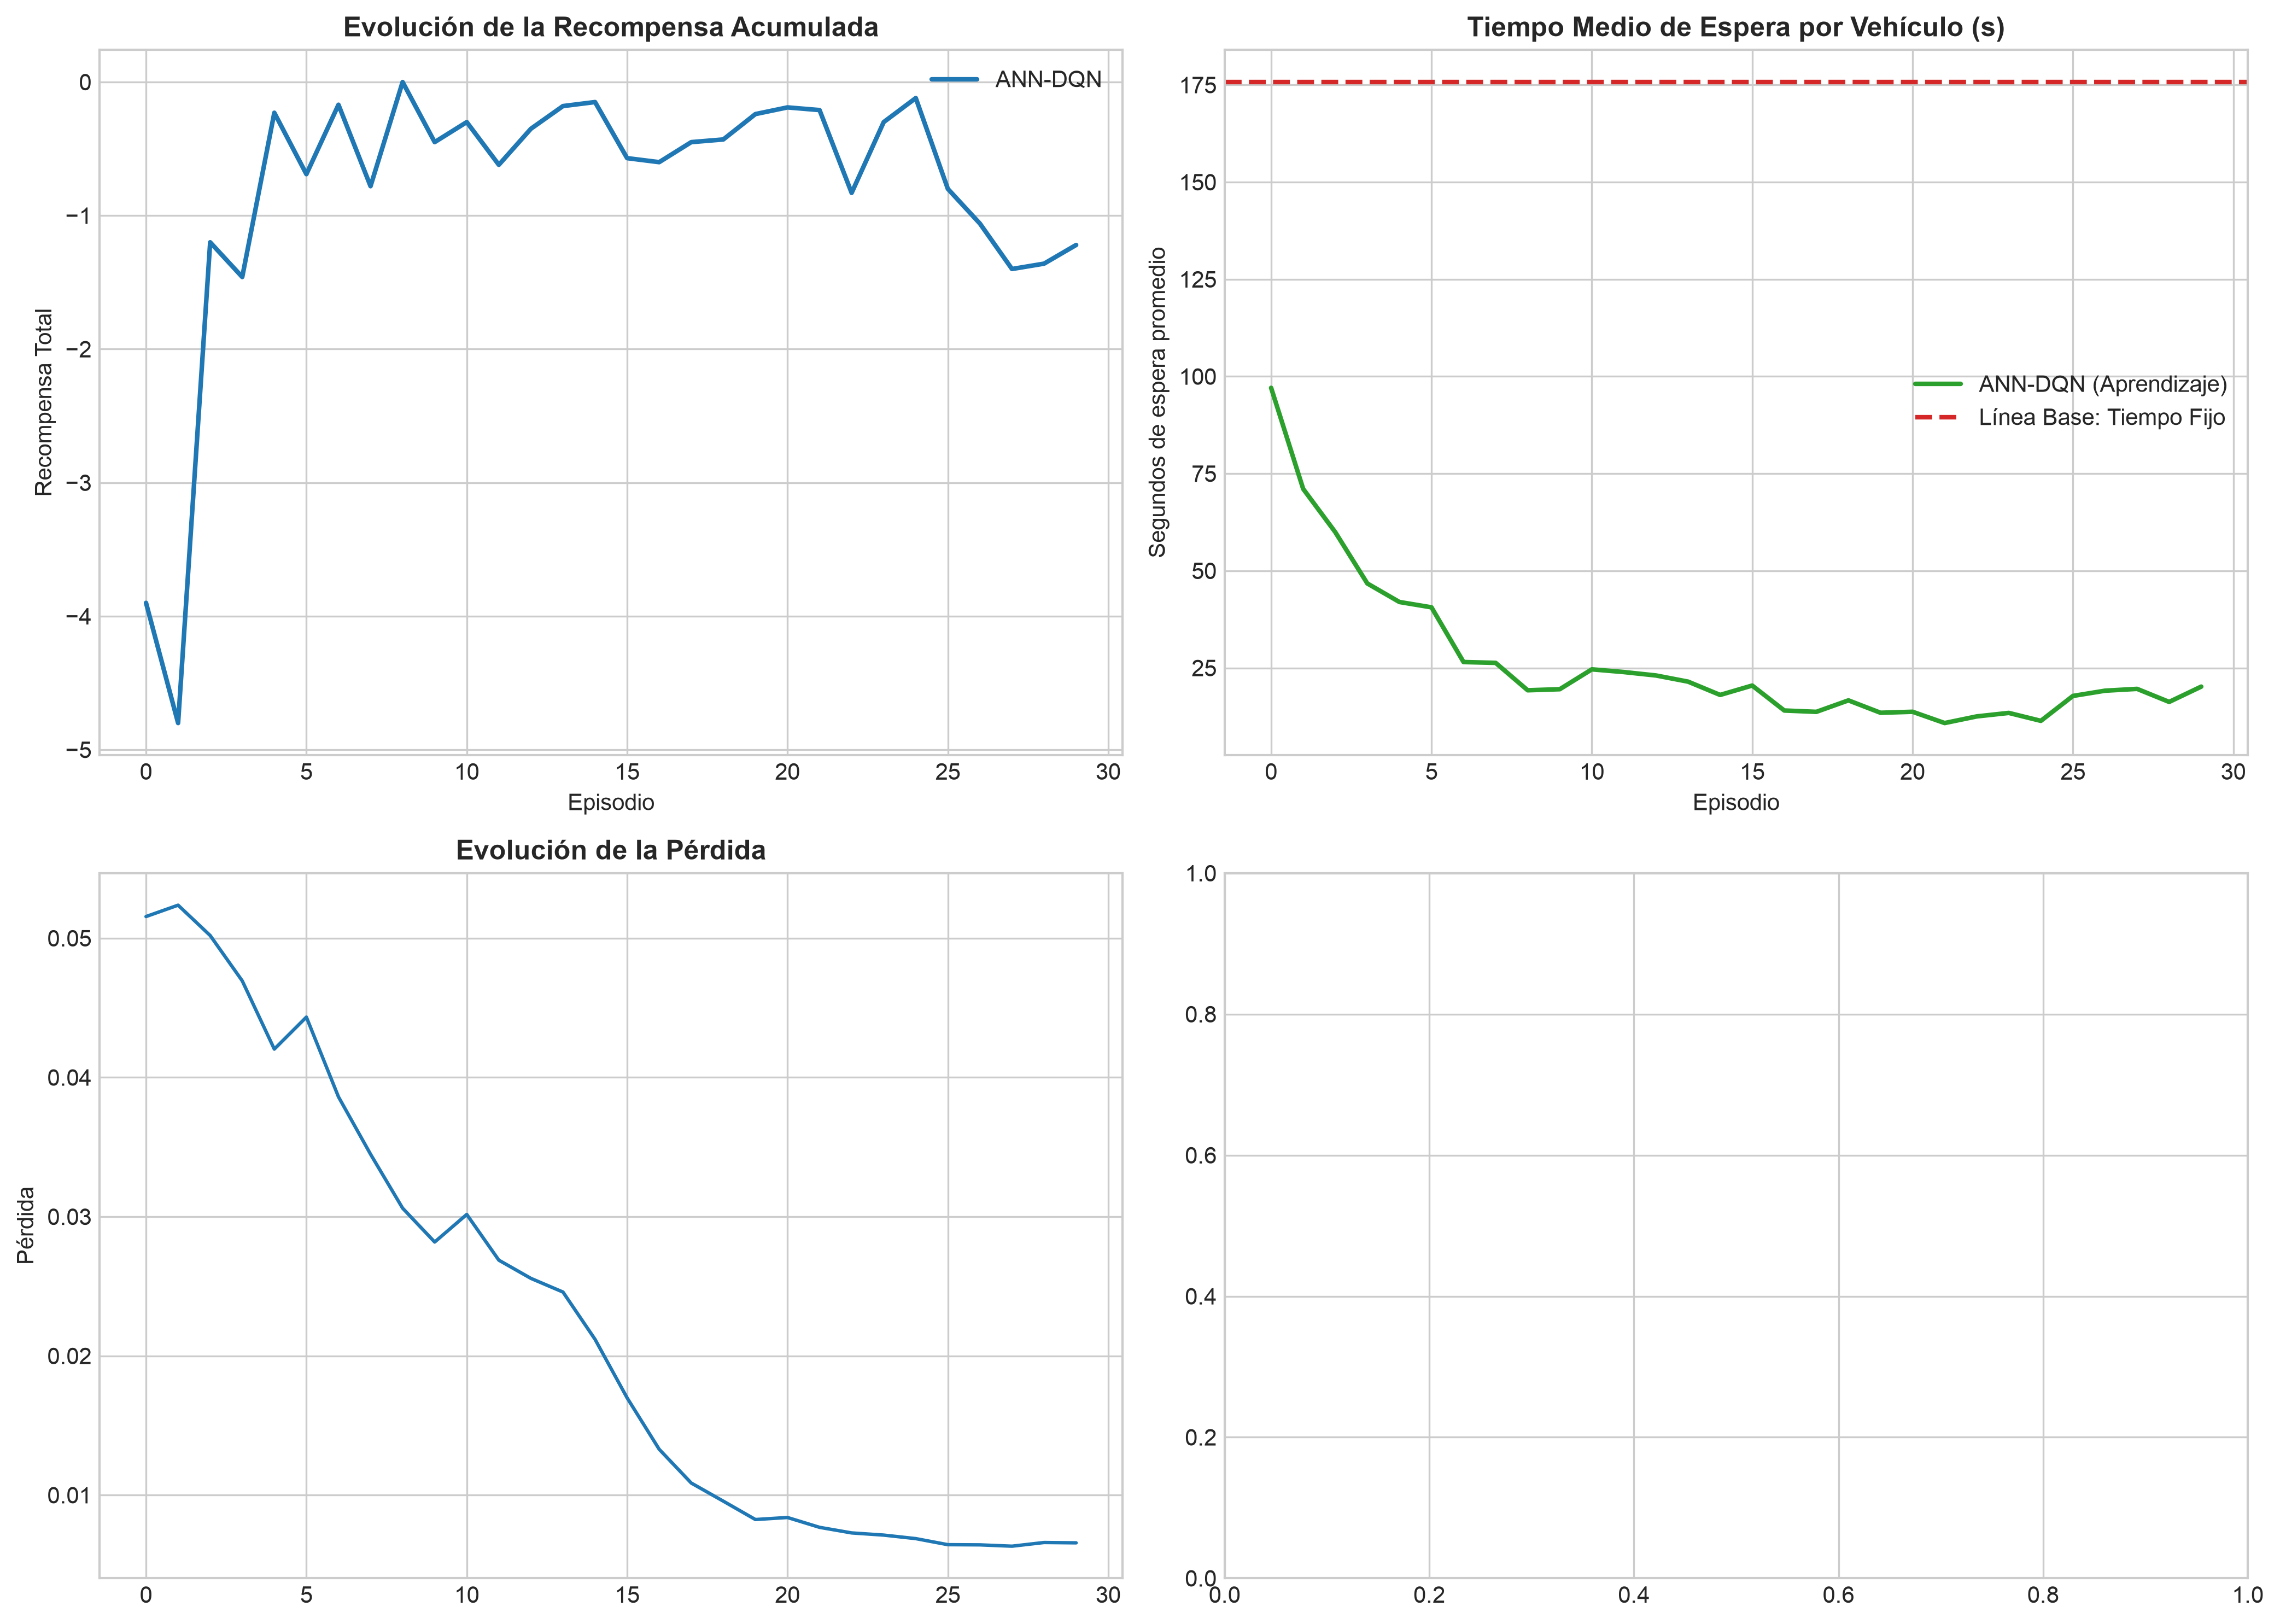

Gráfica guardada con éxito como 'resultados_baseline.png'


In [23]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=300)

# Gráfico 1: Recompensa por episodio
axes[0][0].plot(reward_history, color='tab:blue', linewidth=2, label='ANN-DQN')
axes[0][0].set_title("Evolución de la Recompensa Acumulada", fontsize=12, fontweight='bold')
axes[0][0].set_xlabel("Episodio")
axes[0][0].set_ylabel("Recompensa Total")
axes[0][0].legend()

# Gráfico 2: Comparativa de Tiempo de Espera (vs. Tiempo Fijo)
axes[0][1].plot(waiting_time_history, color='tab:green', linewidth=2, label='ANN-DQN (Aprendizaje)')
axes[0][1].axhline(y=fixed_baseline_wt, color='tab:red', linestyle='--', linewidth=2, label='Línea Base: Tiempo Fijo')
axes[0][1].set_title("Tiempo Medio de Espera por Vehículo (s)", fontsize=12, fontweight='bold')
axes[0][1].set_xlabel("Episodio")
axes[0][1].set_ylabel("Segundos de espera promedio")
axes[0][1].legend()

axes[1][0].plot(loss_history)
axes[1][0].set_title("Evolución de la Pérdida", fontsize=12, fontweight='bold')
# axes[1][0].set_xlabel("Tiempo")
axes[1][0].set_ylabel("Pérdida")
# axes[1][0].legend()

plt.tight_layout()
plt.savefig("resultados_baseline.png")
plt.show()

print("Gráfica guardada con éxito como 'resultados_baseline.png'")

In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
import snntorch as snn
from snntorch import surrogate

class SpikingDQN(nn.Module):
    def __init__(self, state_dim, action_dim, num_steps=8, beta=0.9):
        super(SpikingDQN, self).__init__()
        self.num_steps = num_steps  # Ventana temporal (T timesteps)
        
        # Gradiente sustituto para permitir backpropagation a través de impulsos no diferenciables
        spike_grad = surrogate.fast_sigmoid(slope=25)
        
        # Capa 1: Entrada continua -> 64 neuronas LIF
        self.fc1 = nn.Linear(state_dim, 64)
        self.lif1 = snn.Leaky(beta=beta, spike_grad=spike_grad)
        
        # Capa 2: 64 neuronas LIF -> 64 neuronas LIF
        self.fc2 = nn.Linear(64, 64)
        self.lif2 = snn.Leaky(beta=beta, spike_grad=spike_grad)
        
        # Capa de Salida: 64 neuronas LIF -> Valores Q (Leaky integrator sin reset para mantener valor continuo)
        self.fc3 = nn.Linear(64, action_dim)
        self.lif3 = snn.Leaky(beta=beta, reset_mechanism="none") # Integra potenciales sin disparar picos

    def forward(self, x):
        """
        x: tensor de estado con forma (batch_size, state_dim)
        Retorna: 
          - q_values: (batch_size, action_dim)
          - total_spikes: contador de picos emitidos (para medir eficiencia / SynOps)
        """
        batch_size = x.size(0)
        
        # Inicializar los potenciales de membrana de cada capa en reposo (0.0 V)
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        mem3 = self.lif3.init_leaky()
        
        mem3_record = []
        spike_count = 0
        
        # Simulación temporal de la SNN a través de 'num_steps' pasos de tiempo
        for t in range(self.num_steps):
            # Inyección de corriente analógica continua (Direct Encoding)
            cur1 = self.fc1(x)
            spk1, mem1 = self.lif1(cur1, mem1)
            
            # Capa oculta: solo transmite información si hay disparos (spikes)
            cur2 = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)
            
            # Capa de salida: integra los impulsos de la capa oculta
            cur3 = self.fc3(spk2)
            _, mem3 = self.lif3(cur3, mem3)
            
            mem3_record.append(mem3)
            
            # Acumulamos los disparos de las capas intermedias para métricas energéticas
            spike_count += spk1.sum().item() + spk2.sum().item()
            
        # El valor Q estimado es el promedio temporal del potencial de membrana de salida
        q_values = torch.stack(mem3_record, dim=0).mean(dim=0)
        
        return q_values, spike_count

In [25]:
class SpikingDQNAgent:
    def __init__(self, state_dim, action_dim, num_steps=8):
        self.action_dim = action_dim
        self.num_steps = num_steps
        self.epsilon = EPS_START
        
        # Redes Spiking principal y objetivo (Target)
        self.policy_net = SpikingDQN(state_dim, action_dim, num_steps=num_steps).to(device)
        self.target_net = SpikingDQN(state_dim, action_dim, num_steps=num_steps).to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()
        
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=LR)
        self.loss_fn = nn.SmoothL1Loss()
        self.memory = ReplayBuffer() # Reutilizamos la misma clase ReplayBuffer

    def select_action(self, state, evaluate=False):
        if not evaluate and random.random() < self.epsilon:
            return random.randrange(self.action_dim), 0
        
        with torch.no_grad():
            state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)
            q_values, spikes = self.policy_net(state_tensor)
            action = q_values.argmax().item()
            return action, spikes

    def update(self):
        if len(self.memory) < BATCH_SIZE:
            return 0.0

        states, actions, rewards, next_states, dones = self.memory.sample(BATCH_SIZE)

        # Q(s, a) con la SNN actual
        curr_q, _ = self.policy_net(states)
        curr_q = curr_q.gather(1, actions.unsqueeze(1)).squeeze(1)

        # Target Q con la Target SNN
        with torch.no_grad():
            max_next_q, _ = self.target_net(next_states)
            max_next_q = max_next_q.max(1)[0]
            target_q = rewards + (1 - dones) * GAMMA * max_next_q

        loss = self.loss_fn(curr_q, target_q)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.item()

    def decay_epsilon(self):
        self.epsilon = max(EPS_END, self.epsilon * EPS_DECAY)

In [26]:
env = make_env()

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

snn_agent = SpikingDQNAgent(state_dim, action_dim, num_steps=8)

snn_reward_history = []
snn_waiting_time_history = []
snn_spike_history = []

print("--- INICIANDO ENTRENAMIENTO DE LA SNN (Spiking-DQN) ---")

for ep in range(1, EPISODES + 1):
    state, info = env.reset()
    done = False
    ep_reward = 0.0
    ep_waiting_time = 0.0
    ep_spikes = 0
    step_count = 0

    while not done:
        action, spikes = snn_agent.select_action(state)
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        snn_agent.memory.push(state, action, reward, next_state, done)
        snn_agent.update()

        state = next_state
        ep_reward += reward
        ep_waiting_time += info.get('system_total_waiting_time', 0)
        ep_spikes += spikes
        step_count += 1

    snn_agent.decay_epsilon()

    if ep % TARGET_UPDATE == 0:
        snn_agent.target_net.load_state_dict(snn_agent.policy_net.state_dict())

    avg_wait = ep_waiting_time / step_count
    avg_spikes_per_step = ep_spikes / step_count

    snn_reward_history.append(ep_reward)
    snn_waiting_time_history.append(avg_wait)
    snn_spike_history.append(avg_spikes_per_step)

    print(f"Episodio {ep}/{EPISODES} | Recompensa: {ep_reward:.1f} | "
          f"Espera: {avg_wait:.2f}s | Spikes/Paso: {avg_spikes_per_step:.1f} | Epsilon: {snn_agent.epsilon:.2f}")

env.close()

# Guardar los pesos del modelo SNN
torch.save(snn_agent.policy_net.state_dict(), "snn_dqn_model.pth")
print("Modelo SNN guardado como 'snn_dqn_model.pth'")

 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)                      
--- INICIANDO ENTRENAMIENTO DE LA SNN (Spiking-DQN) ---
 Retrying in 1 seconds
Episodio 1/30 | Recompensa: -8.8 | Espera: 96.08s | Spikes/Paso: 0.0 | Epsilon: 0.90
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 22ms, vehicles TOT 2140 ACT 38 BUF 361)             
 Retrying in 1 seconds
Episodio 2/30 | Recompensa: -0.8 | Espera: 72.10s | Spikes/Paso: 8.5 | Epsilon: 0.81
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 22ms, vehicles TOT 2315 ACT 40 BUF 210)             
 Retrying in 1 seconds
Episodio 3/30 | Recompensa: -1.6 | Espera: 56.26s | Spikes/Paso: 14.3 | Epsilon: 0.73
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 23ms, vehicles TOT 2316 ACT 36 BUF 127)             
 Retrying in 1 seconds
Episodio 4/30 | Recompensa: -1.1 | Espera: 49.55s | Spikes/Paso: 22.7 | Epsilon: 0.66
Step #3600.00 (1ms ~= 1000.00*RT, ~42000.00UPS, TraCI: 25ms, vehicles TOT 2506 ACT 42 BUF 
 Retrying in 1 seconds
Episodio 5

In [29]:
def test_generalization2(agent, n_tests=5):
    print("--- INICIANDO TEST DE EVALUACIÓN (GENERALIZACIÓN) ---")
    
    waiting_times = []
    queues = []
    
    for test_idx in range(n_tests):
        # Usamos una semilla completamente nueva para cada test
        test_seed = 1000 + test_idx
        
        test_env = SumoEnvironment(
            net_file=NET_FILE,
            route_file=ROUTE_FILE,
            use_gui=False,
            num_seconds=SIM_SECONDS,
            delta_time=DELTA_TIME,
            single_agent=True
        )
        
        # Iniciar simulación con la nueva semilla
        state, info = test_env.reset(seed=test_seed)
        done = False
        ep_waiting_time = 0
        ep_queue = 0
        steps = 0
        
        while not done:
            # evaluate=True: La red toma el 100% del control (cero exploración)
            action, spikes = agent.select_action(state, evaluate=True)
            next_state, reward, terminated, truncated, info = test_env.step(action)
            done = terminated or truncated
            
            # Extraer métricas reales de SUMO
            ep_waiting_time += info.get('system_total_waiting_time', 0)
            ep_queue += info.get('system_total_stopped', 0) # Autos totalmente parados
            steps += 1
            state = next_state
            
        test_env.close()
        
        avg_wait = ep_waiting_time / steps
        avg_q = ep_queue / steps
        waiting_times.append(avg_wait)
        queues.append(avg_q)
        
        print(f"Test {test_idx + 1} (Semilla {test_seed}) -> Espera media: {avg_wait:.2f} s | Cola media: {avg_q:.2f} autos")
        
    print("\n--- RESULTADOS FINALES DE GENERALIZACIÓN ---")
    print(f"Tiempo de espera: {np.mean(waiting_times):.2f} ± {np.std(waiting_times):.2f} s")
    print(f"Longitud de cola: {np.mean(queues):.2f} ± {np.std(queues):.2f} autos")

test_generalization2(snn_agent, n_tests=5)

--- INICIANDO TEST DE EVALUACIÓN (GENERALIZACIÓN) ---
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 4ms, vehicles TOT 2513 ACT 20 BUF 0)                
Test 1 (Semilla 1000) -> Espera media: 12.78 s | Cola media: 3.10 autos
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 2ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 5ms, vehicles TOT 2554 ACT 29 BUF 0)                
Test 2 (Semilla 1001) -> Espera media: 17.30 s | Cola media: 4.92 autos
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 2ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 4ms, vehicles TOT 2494 ACT 23 BUF 0)                
Test 3 (Semilla 1002) -> Espera media: 13.25 s | Cola media: 3.20 autos
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS


================= COMPARATIVA DE RESULTADOS =================
Línea Base 1 (Tiempo Fijo)   | Espera: 175.76 s | Costo: 0 Ops
Línea Base 2 (ANN Clásica)   | Espera: 20.19 s | Costo: 4928 MACs (Multiplicaciones)
Propuesta    (Spiking-DQN)   | Espera: 13.18 s | Costo: ~545 SynOps (Adiciones)


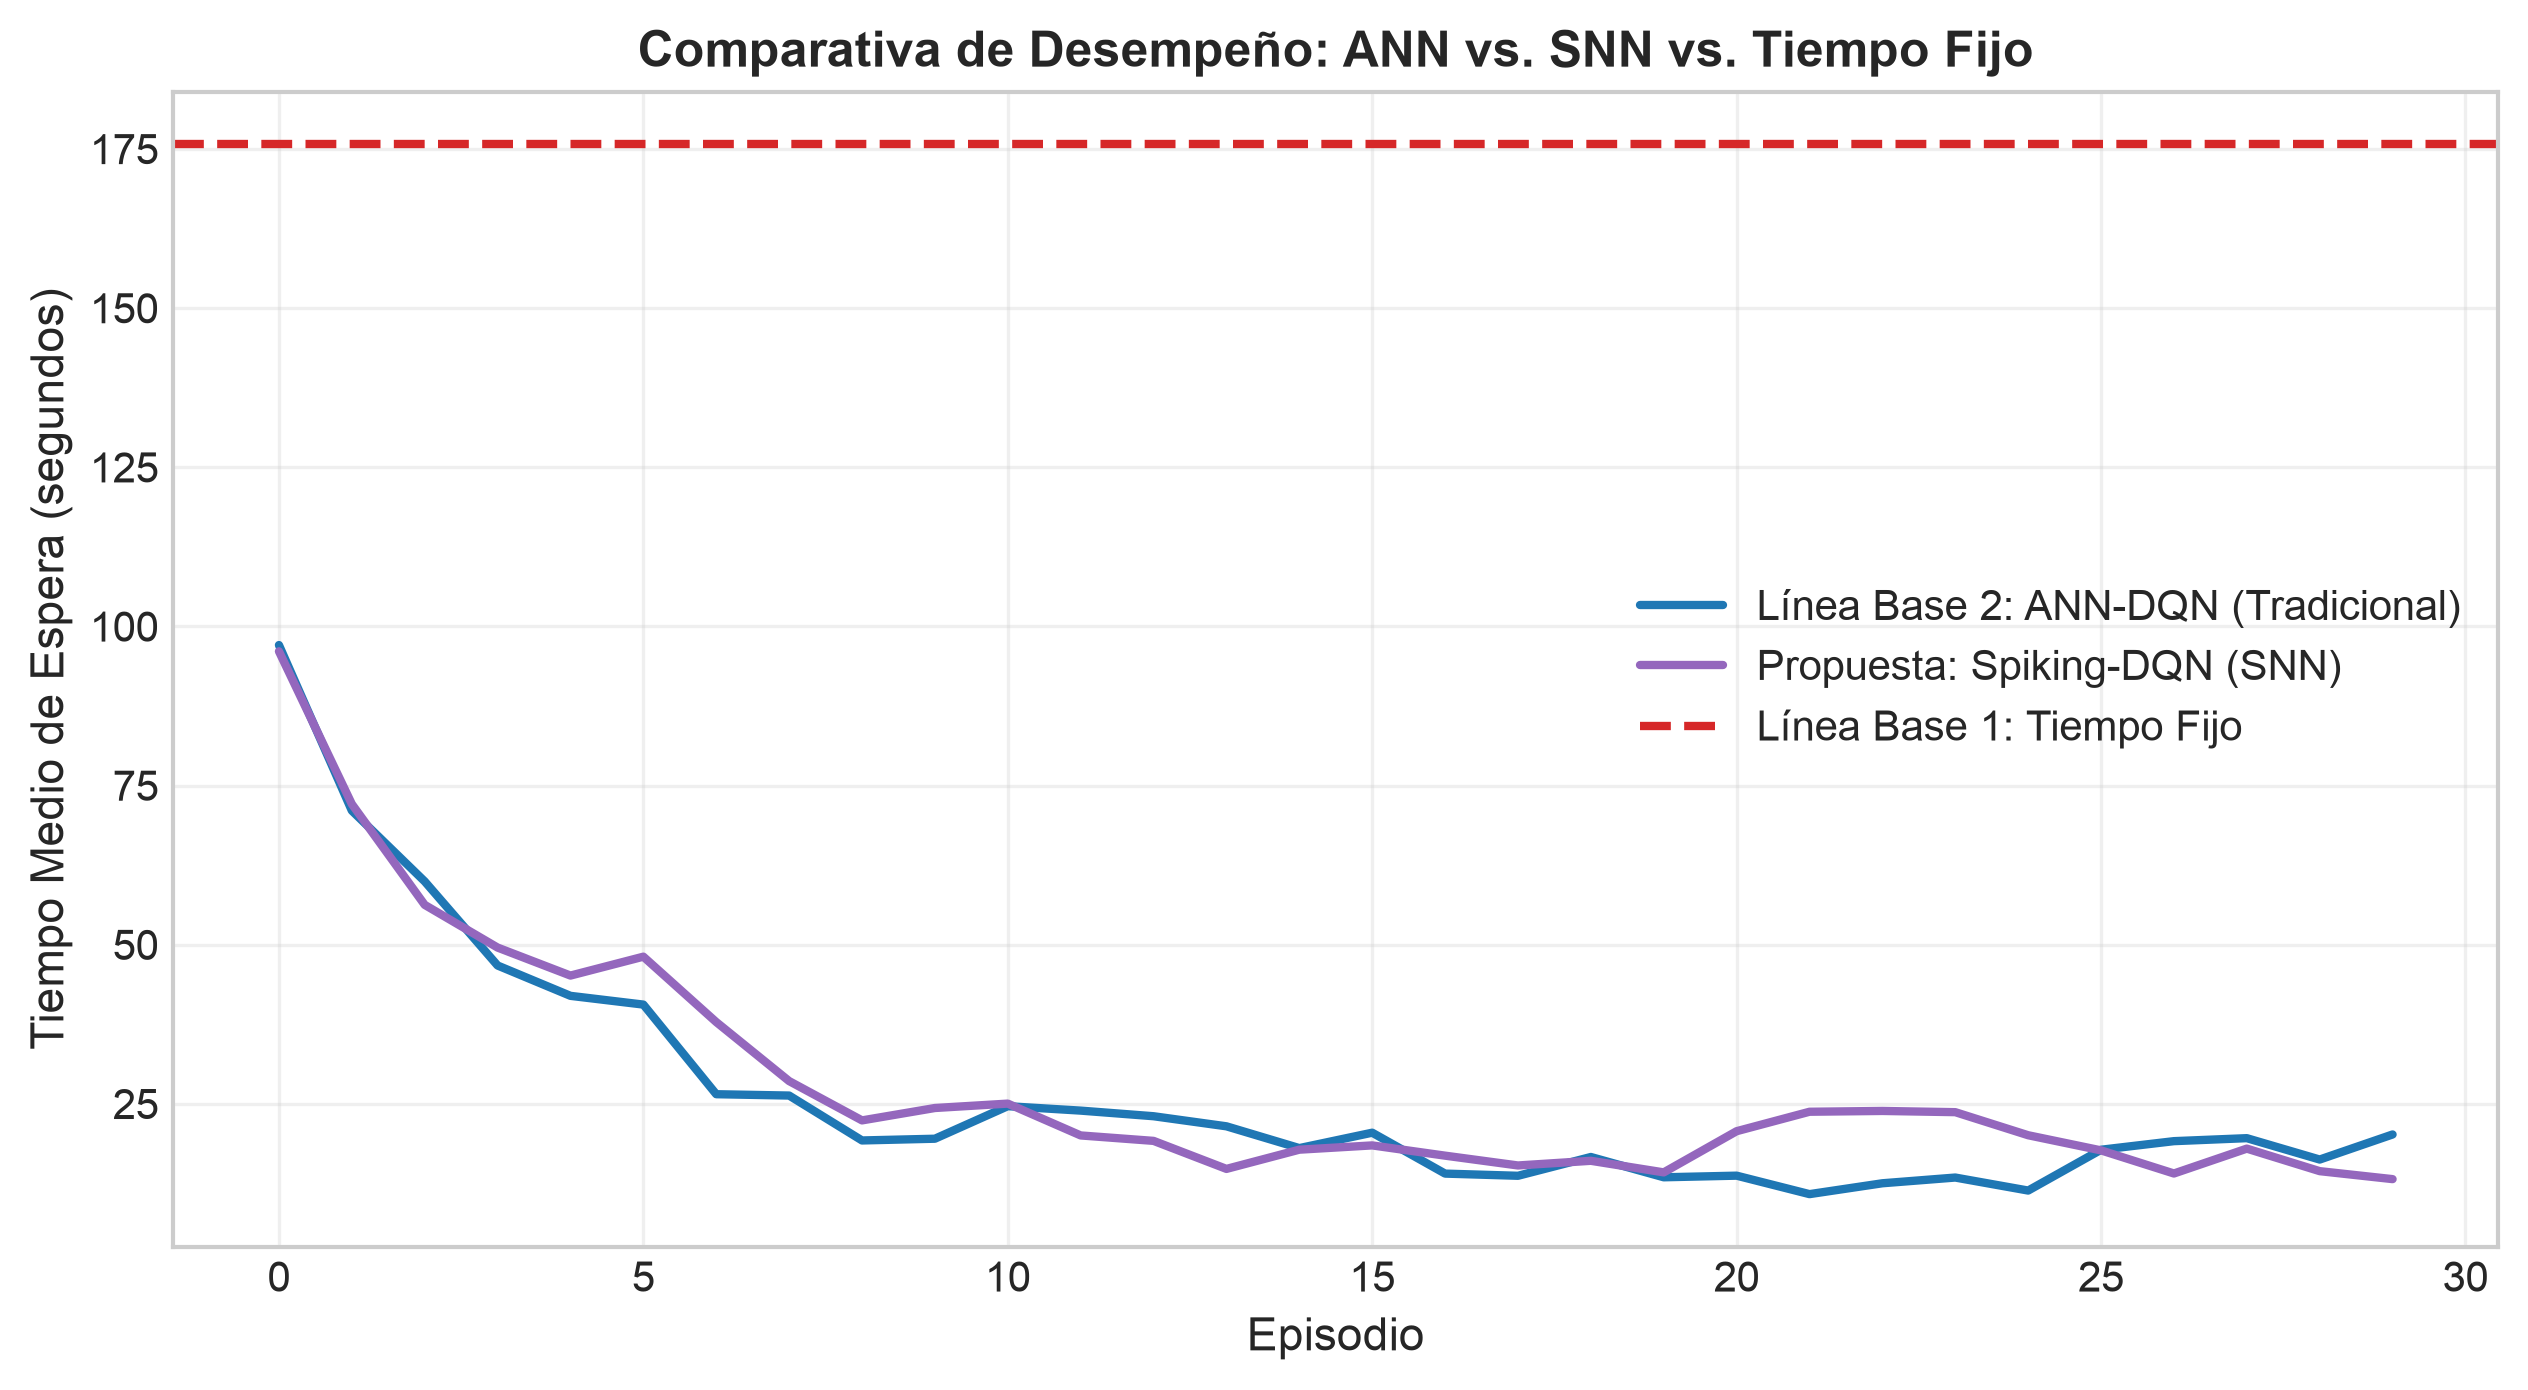

In [27]:
import matplotlib.pyplot as plt

# 1. Costo teórico de operaciones por inferencia
# Para la ANN clásica: todas las conexiones se multiplican densamente (MACs)
ann_macs = (state_dim * 64) + (64 * 64) + (64 * action_dim)

# Para la SNN: operaciones sinápticas (SynOps) proporcionales a los picos emitidos
avg_spikes_inference = np.mean(snn_spike_history[-5:]) # Promedio de los últimos episodios
# Capa 1 es corriente continua, capa 2 y 3 solo operan con sumas cuando hay disparos
snn_synops = (avg_spikes_inference / snn_agent.num_steps) * 64 

print("\n================= COMPARATIVA DE RESULTADOS =================")
print(f"Línea Base 1 (Tiempo Fijo)   | Espera: {fixed_baseline_wt:.2f} s | Costo: 0 Ops")
print(f"Línea Base 2 (ANN Clásica)   | Espera: {waiting_time_history[-1]:.2f} s | Costo: {ann_macs} MACs (Multiplicaciones)")
print(f"Propuesta    (Spiking-DQN)   | Espera: {snn_waiting_time_history[-1]:.2f} s | Costo: ~{int(snn_synops)} SynOps (Adiciones)")
print("=============================================================")

# 2. Gráfica comparativa de desempeño temporal
plt.figure(figsize=(10, 5), dpi=300)
plt.plot(waiting_time_history, label='Línea Base 2: ANN-DQN (Tradicional)', color='tab:blue', linewidth=2)
plt.plot(snn_waiting_time_history, label='Propuesta: Spiking-DQN (SNN)', color='tab:purple', linewidth=2)
plt.axhline(y=fixed_baseline_wt, label='Línea Base 1: Tiempo Fijo', color='tab:red', linestyle='--', linewidth=2)

plt.title("Comparativa de Desempeño: ANN vs. SNN vs. Tiempo Fijo", fontsize=12, fontweight='bold')
plt.xlabel("Episodio", fontsize=11)
plt.ylabel("Tiempo Medio de Espera (segundos)", fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.savefig("comparativa_ann_vs_snn.png")
plt.show()

In [31]:
import time

# Vector de prueba aleatorio simulando el tráfico
dummy_state = torch.randn(1, state_dim).to(device)

# Calentar el procesador (warmup)
for _ in range(50):
    _ = agent.policy_net(dummy_state)
    _ = snn_agent.policy_net(dummy_state)

# 1. Medir latencia de la ANN Clásica (1000 iteraciones)
start_time = time.perf_counter()
with torch.no_grad():
    for _ in range(1000):
        _ = agent.policy_net(dummy_state)
ann_latency = (time.perf_counter() - start_time) / 1000 * 1000 # en milisegundos

# 2. Medir latencia de la SNN (1000 iteraciones)
start_time = time.perf_counter()
with torch.no_grad():
    for _ in range(1000):
        _, _ = snn_agent.policy_net(dummy_state)
snn_latency = (time.perf_counter() - start_time) / 1000 * 1000 # en milisegundos

print(f"Latencia ANN : {ann_latency:.4f} ms por inferencia")
print(f"Latencia SNN : {snn_latency:.4f} ms por inferencia")

Latencia ANN : 0.1237 ms por inferencia
Latencia SNN : 8.2228 ms por inferencia
